# 01 — Official Validation Leaderboard & Candidate Tiering

Bảng xếp hạng chính thức 72 kịch bản theo Protocol §9.3 & §18: Phân tầng dung sai ε = 10^-4 mm trên Pooled MAE, giải hòa bằng Pooled RMSE chưa làm tròn, và Canonical Model ID theo thứ tự từ điển.

### Project Guardrails & Execution Baseline:
- **Protocol Căn cứ:** `training_forecasting_evaluation_protocol_v1_0_21.md` và `spec_module_result_analysis_v2.md`
- **Zero Final Test Access Rule:** Chỉ nạp dữ liệu Validation (724 origins, 2018-05-01 đến 2020-04-23, H=7).
- **Purged Metrics Integrity:** Tuyệt đối không tính hoặc hiển thị CR-MAE@7, CR-Bias@7, RainDay-MAE, hay Bias.
- **Descriptive Cost Principle:** Số liệu tài nguyên chỉ dùng mô tả (PROP-07), không dùng để xếp hạng mô hình.


In [1]:
# Bootstrap root directory
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

ROOT_DIR = Path.cwd()
while not (ROOT_DIR / 'src').exists() and ROOT_DIR != ROOT_DIR.parent:
    ROOT_DIR = ROOT_DIR.parent
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))


OFFICIAL VALIDATION LEADERBOARD (Top 25 Forecasters):


,rank,tier_id,is_tied,scenario_id,model,canonical_model_id,family,strategy,feature_set,MAE,MSE,RMSE,MASE,training_time,inference_time,selected_hurdle_threshold,status
0,1,Tier-1,False,SC-30,lightgbm_tweedie_F2,lightgbm_tweedie_f2,Tabular ML Tweedie,ML Tweedie (F2),F2,3.1485,44.7202,6.6873,0.8506,5.44s,0.0154s,NaN,COMPLETED
1,2,Tier-2,False,SC-34,xgboost_tweedie_F2,xgboost_tweedie_f2,Tabular ML Tweedie,ML Tweedie (F2),F2,3.1565,43.9801,6.6318,0.8528,2.31s,0.0123s,NaN,COMPLETED
2,3,Tier-3,False,SC-29,lightgbm_tweedie_F1,lightgbm_tweedie_f1,Tabular ML Tweedie,ML Tweedie (F1),F1,3.1584,44.4747,6.6689,0.8533,5.82s,0.0403s,NaN,COMPLETED
3,4,Tier-4,False,SC-35,xgboost_tweedie_F3,xgboost_tweedie_f3,Tabular ML Tweedie,ML Tweedie (F3),F3,3.1683,44.1362,6.6435,0.8559,2.13s,0.0100s,NaN,COMPLETED
4,5,Tier-5,False,SC-33,xgboost_tweedie_F1,xgboost_tweedie_f1,Tabular ML Tweedie,ML Tweedie (F1),F1,3.1695,44.1210,6.6424,0.8563,1.73s,0.0090s,NaN,COMPLETED
5,6,Tier-6,False,SC-31,lightgbm_tweedie_F3,lightgbm_tweedie_f3,Tabular ML Tweedie,ML Tweedie (F3),F3,3.1939,45.0652,6.7131,0.8629,1.70s,0.0167s,NaN,COMPLETED
6,7,Tier-7,False,SC-32,xgboost_tweedie_F0,xgboost_tweedie_f0,Tabular ML Tweedie,ML Tweedie (F0),F0,3.2331,44.9638,6.7055,0.8734,1.92s,0.0105s,NaN,COMPLETED
7,8,Tier-8,False,SC-28,lightgbm_tweedie_F0,lightgbm_tweedie_f0,Tabular ML Tweedie,ML Tweedie (F0),F0,3.2377,45.4657,6.7428,0.8747,1.40s,0.0185s,NaN,COMPLETED
8,9,Tier-9,False,SC-42,logistic_linear_stratA_F1,logistic_linear_strata_f1,Two-Stage Hurdle,Mixture Expectation,F1,3.3187,44.7659,6.6907,0.8966,0.71s,0.0060s,NaN,COMPLETED
9,10,Tier-10,False,SC-44,logistic_linear_stratA_F3,logistic_linear_strata_f3,Two-Stage Hurdle,Mixture Expectation,F3,3.3341,45.0236,6.7100,0.9007,0.68s,0.0050s,NaN,COMPLETED


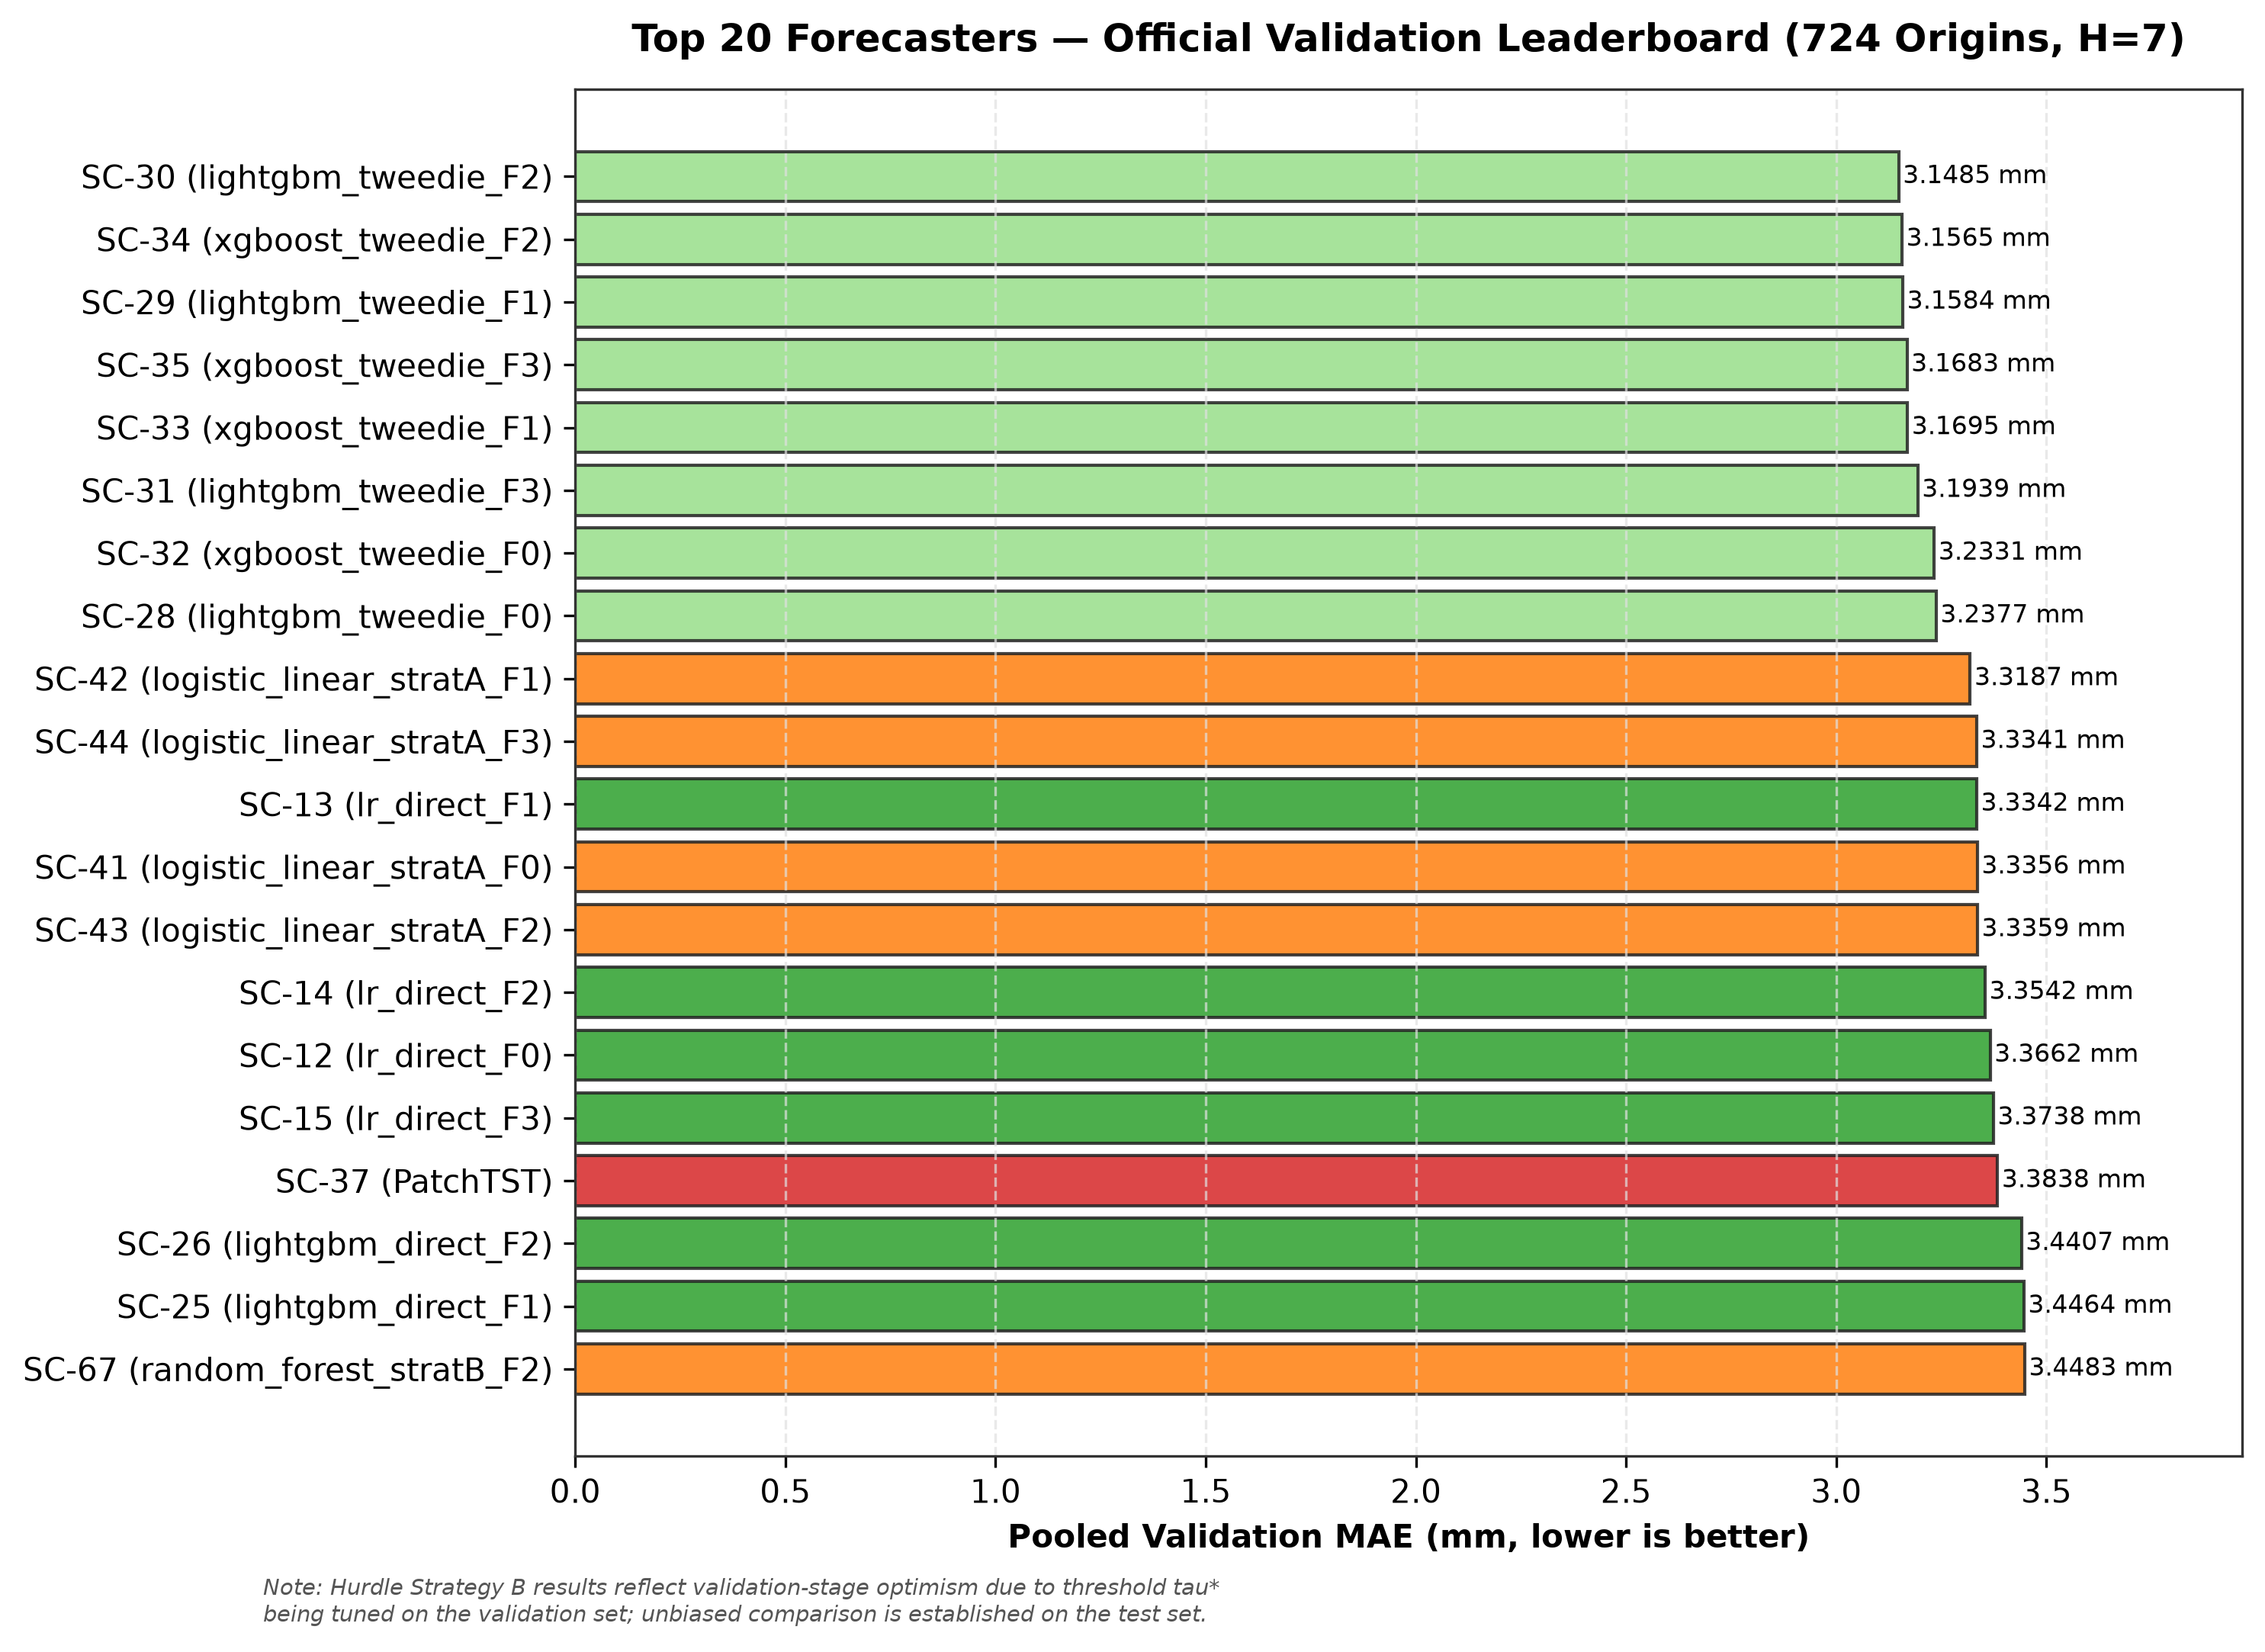

In [2]:
from src.analysis.loaders import load_all_validation_results
from src.analysis.ranking import compute_official_leaderboard, format_leaderboard_display
from src.analysis.plotting import plot_official_leaderboard
import pandas as pd

# 1. Compute official ranking
df_results = load_all_validation_results()
df_ranked = compute_official_leaderboard(df_results)

# 2. Format and display Top 25
print("OFFICIAL VALIDATION LEADERBOARD (Top 25 Forecasters):")
df_disp = format_leaderboard_display(df_ranked, top_n=25)
display(df_disp)

# 3. Plot Top 20
fig = plot_official_leaderboard(df_ranked, top_n=20, save_name="fig01_top_leaderboard.png")
